# Auxiliary Operations — Ancilla Management: Reset & Reuse (Qiskit)

**Primitive demonstrated:** *Ancilla management* — mid-circuit **measurement + reset** of a
single physical ancilla qubit so it can be **reused** for a second, independent round of
computation instead of allocating a second physical qubit. This is the standard
resource-saving "qubit reuse" pattern used on real NISQ hardware (Qiskit calls this a
*dynamic circuit*).

## SETUP (identical in the CUDA-Q notebook — do not diverge)
- **N QUBITS:** 3 → `q0`, `q1` = data qubits, `q2` = the single ancilla, **reused twice**
- **Gate sequence:**
  - **Round 1:** `H(q0)` → `CX(q0 → q2)` → **measure `q2` into `c0`** → **reset `q2`**
  - **Round 2:** `H(q1)` → `CX(q1 → q2)` → **measure `q2` into `c1`**
- **QUBIT ORDERING CONTRACT:** qubit 0 = rightmost bit in every printed bitstring. Classical
  bit 0 (`c0`) is likewise the rightmost bit of the 2-bit joint counts string (Qiskit's
  native convention — no reversal needed in this notebook).
- **SHOTS:** 4000, **SEED:** 42
- **GLOBAL PHASE CONVENTION:** identical function used in both notebooks (applied to the
  pre-measurement reference statevectors below, since the full dynamic circuit contains
  non-unitary reset/measure instructions and has no single fixed statevector of its own).
- **Basis ordering for matrices:** `{|00>, |01>, |10>, |11>}` ascending binary order.

## Theory recap
Round 1 prepares the 2-qubit state `(1/√2)(|q0=0,q2=0> + |q0=1,q2=1>)` (a Bell pair between
`q0` and the ancilla). Measuring `q2` collapses it to a uniformly random bit
`c0 ∈ {0,1}`, each with probability 1/2 — and `q0` collapses to match, but we don't use `q0`
again so that's irrelevant here. **`reset(q2)` then unconditionally forces the ancilla back
to `|0>`, regardless of the measurement outcome** — by the definition of the reset channel,
this erases any correlation with round 1 before round 2 begins.

Round 2 is then just `H(q1)` → `CX(q1 → q2)` → measure, on a fresh `|0>` ancilla — identical
in form to round 1 but on `q1`. So the hand-derived expected result is:

`P(c0=0) = P(c0=1) = 1/2`,  `P(c1=0) = P(c1=1) = 1/2`, **and `c0`, `c1` are statistically
independent** (the whole point of resetting the ancilla between rounds) — so the joint
distribution over `(c1,c0)` should be uniform over all four 2-bit outcomes, each ≈ 0.25.

**Ordering-convention warning:** Qiskit already indexes qubit 0 (and classical bit 0) as the
rightmost bit of every printed string — no reversal is applied in this notebook.

**Run all cells top to bottom.**


In [1]:
# Install cell.
!pip install -q qiskit qiskit-aer pylatexenc


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 39.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 53.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 38.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.3 MB/s eta 0:00:00


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator

N_QUBITS = 3       # q0, q1 = data qubits, q2 = ancilla (reused)
DATA_Q0 = 0
DATA_Q1 = 1
ANCILLA = 2
SHOTS = 4000
SEED = 42

print("N_QUBITS:", N_QUBITS, " ANCILLA:", ANCILLA, " SHOTS:", SHOTS, " SEED:", SEED)


N_QUBITS: 3  ANCILLA: 2  SHOTS: 4000  SEED: 42


In [3]:
# Build the FULL dynamic circuit: measure -> reset -> reuse. This contains non-unitary
# instructions (measure, reset), so it CANNOT be passed to Statevector()/Operator() --
# those calls only accept purely unitary circuits. A measurement-free reference circuit
# for each round is built separately in the next cell for the matrix/statevector cross-check.

qreg = QuantumRegister(N_QUBITS, "q")
creg = ClassicalRegister(2, "c")   # c[0] = round-1 outcome, c[1] = round-2 outcome
qc = QuantumCircuit(qreg, creg, name="ancilla_management")

# --- Round 1: use the ancilla, measure it, then reclaim it ---
qc.h(DATA_Q0)                 # data qubit q0 into superposition
qc.cx(DATA_Q0, ANCILLA)       # entangle ancilla with q0 (Bell pair)
qc.measure(ANCILLA, creg[0])  # collapse the ancilla -> classical bit c0
qc.reset(ANCILLA)             # unconditionally force the ancilla back to |0> for reuse
qc.barrier()

# --- Round 2: reuse the SAME physical ancilla qubit for an independent computation ---
qc.h(DATA_Q1)                 # data qubit q1 into superposition
qc.cx(DATA_Q1, ANCILLA)       # entangle the (freshly reset) ancilla with q1
qc.measure(ANCILLA, creg[1])  # collapse the ancilla -> classical bit c1

print(qc)


     ┌───┐              ░              
q_0: ┤ H ├──■───────────░──────────────
     └───┘  │           ░ ┌───┐        
q_1: ───────┼───────────░─┤ H ├──■─────
          ┌─┴─┐┌─┐      ░ └───┘┌─┴─┐┌─┐
q_2: ─────┤ X ├┤M├─|0>──░──────┤ X ├┤M├
          └───┘└╥┘      ░      └───┘└╥┘
c: 2/═══════════╩════════════════════╩═
                0                    1 


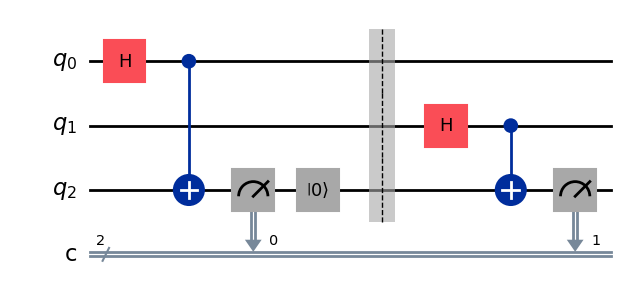

In [4]:
# Draw the full dynamic circuit with matplotlib and save it.
fig = qc.draw(output="mpl")
fig.savefig("ancilla_management_qiskit_circuit.png", dpi=150, bbox_inches="tight")
fig


In [5]:
# Explicit matrix representation + statevector cross-check, done on the PRE-MEASUREMENT
# unitary part of round 1 only (H(q0), CX(q0,ancilla)) -- the only portion of this circuit
# that is a fixed pure state before any non-unitary instruction is applied. Round 2's
# pre-measurement state is the same construction applied to q1 on a freshly-reset ancilla,
# i.e. an identical Bell pair by symmetry -- so verifying round 1 verifies both.

H = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
I2 = np.eye(2, dtype=complex)
print("H gate matrix:\n", np.round(H, 4))
print("\nX gate matrix (inside CNOT):\n", np.round(X, 4))

def cnot_matrix(n_qubits, control, target):
    dim = 2 ** n_qubits
    mat = np.zeros((dim, dim), dtype=complex)
    for basis_index in range(dim):
        bits = [(basis_index >> q) & 1 for q in range(n_qubits)]
        if bits[control] == 1:
            bits[target] ^= 1
        new_index = sum(bit << q for q, bit in enumerate(bits))
        mat[new_index, basis_index] = 1.0
    return mat

# 2-qubit reference: (q0, ancilla) relabeled locally as (qubit 0, qubit 1)
H_on_0 = np.kron(I2, H)
CX_0_to_1 = cnot_matrix(2, control=0, target=1)
U_manual_round1 = CX_0_to_1 @ H_on_0

round1_ref = QuantumCircuit(2, name="round1_unitary_only")
round1_ref.h(0)
round1_ref.cx(0, 1)
U_qiskit_round1 = Operator(round1_ref).data

max_diff = np.max(np.abs(U_manual_round1 - U_qiskit_round1))
print("\nMax |U_manual_round1 - U_qiskit_round1| =", max_diff)
assert max_diff < 1e-9, "Manual and Qiskit-extracted round-1 unitaries disagree!"
print("Manual hand-built matrix and Qiskit Operator(round1_ref) MATCH.")

print("\nRound-1 pre-measurement unitary (rounded, basis = |q_ancilla q0>):")
print(np.round(U_manual_round1, 4))


H gate matrix:
 [[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]

X gate matrix (inside CNOT):
 [[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]

Max |U_manual_round1 - U_qiskit_round1| = 0.0
Manual hand-built matrix and Qiskit Operator(round1_ref) MATCH.

Round-1 pre-measurement unitary (rounded, basis = |q_ancilla q0>):
[[ 0.7071+0.j  0.7071+0.j  0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j -0.7071+0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j  0.    +0.j  0.    +0.j]]


In [6]:
# Exact statevector cell (round-1 pre-measurement reference circuit only).
sv = Statevector(round1_ref)
amps = sv.data.copy()

def normalize_global_phase(amplitudes, tol=1e-9):
    for amp in amplitudes:
        if abs(amp) > tol:
            phase = np.angle(amp)
            return amplitudes * np.exp(-1j * phase)
    return amplitudes

amps_normalized = normalize_global_phase(amps)

n = 2
prob_dict = {}
for idx in range(2 ** n):
    bitstring = format(idx, f"0{n}b")
    prob_dict[bitstring] = float(np.abs(amps_normalized[idx]) ** 2)

print("Round-1 pre-measurement probabilities (bitstring = ancilla,q0), phase-normalized:")
QISKIT_ROUND1_STATEVECTOR_PROBS = dict(sorted(prob_dict.items()))
print(QISKIT_ROUND1_STATEVECTOR_PROBS)
print("\n(Round 2's pre-measurement state on (q1, freshly-reset ancilla) is identical by")
print("construction/symmetry, since reset always returns the ancilla to |0> before round 2.)")


Round-1 pre-measurement probabilities (bitstring = ancilla,q0), phase-normalized:
{'00': 0.4999999999999999, '01': 0.0, '10': 0.0, '11': 0.4999999999999999}

(Round 2's pre-measurement state on (q1, freshly-reset ancilla) is identical by
construction/symmetry, since reset always returns the ancilla to |0> before round 2.)


### Ordering-fix note
Qiskit already indexes qubit 0 (and classical bit `c[0]`) as the rightmost bit of every
printed string — **no reversal was applied** in this notebook. The CUDA-Q companion notebook
uses the opposite (MSB-first) convention internally and explicitly reverses its output to
match this one.


In [7]:
# Measurement cell: run the FULL dynamic circuit (measure -> reset -> reuse -> measure).
sim = AerSimulator(seed_simulator=SEED)
job = sim.run(qc, shots=SHOTS, seed_simulator=SEED)
joint_counts = job.result().get_counts()   # keys are "c1c0" (c0 = rightmost, Qiskit convention)
total = sum(joint_counts.values())

# Marginals for each round, derived from the joint counts.
c0_counts = {"0": 0, "1": 0}
c1_counts = {"0": 0, "1": 0}
for bitstring, count in joint_counts.items():
    c0_counts[bitstring[-1]] += count   # rightmost char = c0
    c1_counts[bitstring[0]] += count    # leftmost char  = c1

QISKIT_MARGINALS = {
    "c0": {k: v / total for k, v in sorted(c0_counts.items())},
    "c1": {k: v / total for k, v in sorted(c1_counts.items())},
}

print("Raw joint counts (bitstring = c1c0):", joint_counts)
print("\nMarginal probabilities:")
print(QISKIT_MARGINALS)

# Bonus (Qiskit-only): joint distribution, to directly verify independence of c0 and c1
# (the real test that reset correctly erased round-1's correlation before round 2).
QISKIT_JOINT_PROBS = {bs: c / total for bs, c in sorted(joint_counts.items())}
print("\nJoint probabilities (bonus, Qiskit-only -- tests c0/c1 independence):")
print(QISKIT_JOINT_PROBS)


Raw joint counts (bitstring = c1c0): {'01': 959, '10': 1007, '00': 993, '11': 1041}

Marginal probabilities:
{'c0': {'0': 0.5, '1': 0.5}, 'c1': {'0': 0.488, '1': 0.512}}

Joint probabilities (bonus, Qiskit-only -- tests c0/c1 independence):
{'00': 0.24825, '01': 0.23975, '10': 0.25175, '11': 0.26025}


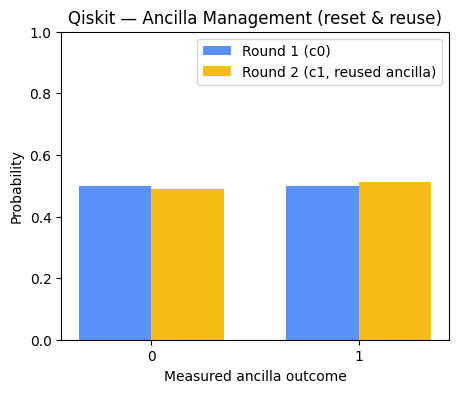

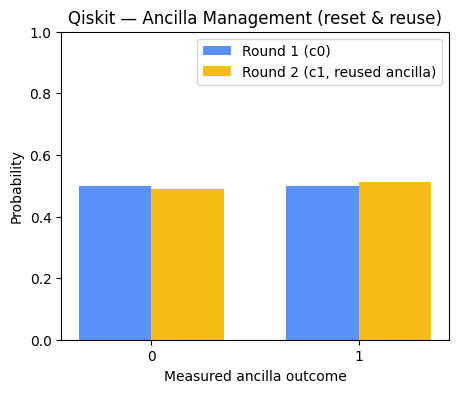

In [8]:
# Histogram -- grouped bar chart comparing round 1 (c0) vs round 2 (c1), same style as
# the CUDA-Q notebook so the two are visually comparable.
fig2, ax = plt.subplots(figsize=(5, 4))
outcomes = ["0", "1"]
x = np.arange(len(outcomes))
width = 0.35

c0_vals = [QISKIT_MARGINALS["c0"][o] for o in outcomes]
c1_vals = [QISKIT_MARGINALS["c1"][o] for o in outcomes]

ax.bar(x - width/2, c0_vals, width, label="Round 1 (c0)", color="#5B8FF9")
ax.bar(x + width/2, c1_vals, width, label="Round 2 (c1, reused ancilla)", color="#F6BD16")
ax.set_xticks(x)
ax.set_xticklabels(outcomes)
ax.set_ylim(0, 1)
ax.set_xlabel("Measured ancilla outcome")
ax.set_ylabel("Probability")
ax.set_title("Qiskit — Ancilla Management (reset & reuse)")
ax.legend()
fig2.savefig("ancilla_management_qiskit_histogram.png", dpi=150, bbox_inches="tight")
fig2


In [9]:
# Resource counts.
print("Circuit depth (full dynamic circuit):", qc.depth())
print("Gate counts (full dynamic circuit):", dict(qc.count_ops()))
print("Note: only 3 qubits are allocated even though 2 independent rounds run, because the")
print("ancilla (q2) is reset and reused instead of allocating a 4th qubit.")


Circuit depth (full dynamic circuit): 7
Gate counts (full dynamic circuit): {'h': 2, 'cx': 2, 'measure': 2, 'reset': 1, 'barrier': 1}
Note: only 3 qubits are allocated even though 2 independent rounds run, because the
ancilla (q2) is reset and reused instead of allocating a 4th qubit.


In [ ]:
# Convention-notes cell (plain text restatement).
print("Bit ordering: qubit/classical-bit 0 = rightmost bit. No reversal applied (Qiskit's")
print("native convention).")
print("Global phase: applied to the round-1 pre-measurement reference statevector only,")
print("since the full circuit is non-unitary (contains measure/reset); it was a no-op here")
print("because the first nonzero amplitude was already real-positive.")
print("Ancilla management: a single physical ancilla qubit (q2) was measured, reset, and")
print("reused for a second, independent round of computation -- no second ancilla qubit")
print("was allocated.")


Bit ordering: qubit/classical-bit 0 = rightmost bit. No reversal applied (Qiskit's
native convention).
Global phase: applied to the round-1 pre-measurement reference statevector only,
since the full circuit is non-unitary (contains measure/reset); it was a no-op here
because the first nonzero amplitude was already real-positive.
Ancilla management: a single physical ancilla qubit (q2) was measured, reset, and
reused for a second, independent round of computation -- no second ancilla qubit
was allocated.


In [10]:
# Final cell: assign and print QISKIT_RESULT.
QISKIT_RESULT = QISKIT_MARGINALS
print("QISKIT_RESULT =", QISKIT_RESULT)


QISKIT_RESULT = {'c0': {'0': 0.5, '1': 0.5}, 'c1': {'0': 0.488, '1': 0.512}}


In [11]:
# Diff-check block (cross-notebook comparison + hand-computed sanity check).
# After running the CUDA-Q notebook, paste its printed CUDAQ_RESULT dict below to compare.

HAND_COMPUTED_EXPECTED = {
    "c0": {"0": 0.5, "1": 0.5},
    "c1": {"0": 0.5, "1": 0.5},
}

max_delta_vs_hand = max(
    abs(QISKIT_RESULT[reg].get(k, 0.0) - HAND_COMPUTED_EXPECTED[reg].get(k, 0.0))
    for reg in ("c0", "c1")
    for k in set(QISKIT_RESULT[reg]) | set(HAND_COMPUTED_EXPECTED[reg])
)
print("Max |QISKIT_RESULT - hand-computed expected| =", max_delta_vs_hand)
assert max_delta_vs_hand < 0.05, "Qiskit shot noise exceeds tolerance vs hand-computed value!"
print("Qiskit result matches the hand-computed expected distribution within tolerance.")

# Bonus independence check (Qiskit-only data): joint probabilities should be close to the
# product of the marginals if reset correctly erased round-1's correlation.
expected_joint = 0.25
max_indep_delta = max(abs(p - expected_joint) for p in QISKIT_JOINT_PROBS.values())
print("Max |joint prob - 0.25| (independence check) =", max_indep_delta)
assert max_indep_delta < 0.08, "c0 and c1 look correlated -- reset may not be working as expected!"
print("c0 and c1 are statistically independent within shot-noise tolerance -- reset worked.")

# --- Uncomment after running the CUDA-Q notebook and pasting its result below ---
# CUDAQ_RESULT = {"c0": {"0": 0.503, "1": 0.497}, "c1": {"0": 0.498, "1": 0.502}}  # <-- paste real result
# max_delta_vs_cudaq = max(
#     abs(QISKIT_RESULT[reg].get(k, 0.0) - CUDAQ_RESULT[reg].get(k, 0.0))
#     for reg in ("c0", "c1")
#     for k in set(QISKIT_RESULT[reg]) | set(CUDAQ_RESULT[reg])
# )
# print("Max |QISKIT_RESULT - CUDAQ_RESULT| =", max_delta_vs_cudaq)
# assert max_delta_vs_cudaq < 1e-1, "Qiskit and CUDA-Q results disagree beyond shot-noise tolerance!"
# print("Qiskit and CUDA-Q results MATCH within tolerance.")


Max |QISKIT_RESULT - hand-computed expected| = 0.01200000000000001
Qiskit result matches the hand-computed expected distribution within tolerance.
Max |joint prob - 0.25| (independence check) = 0.010250000000000009
c0 and c1 are statistically independent within shot-noise tolerance -- reset worked.
